**Aim:** Identify sun groups of neuronal cells

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)

___
Austen:
> While I’m gone, would you please do the following and we can meet next week to discuss?

> - [x] For all neurons, please generate a bar graph showing the percent of total cells in each condition that are drd1+, drd2+, adora2a+, or ppp1r1b+
> - [x] Subcluster neuronal clusters 0, 1 and 3 and generate a UMAP displaying treatment conditions to see if we can better separate MDMA and Meth activated cells
> - [x] Generate a UMAP for neurons highlighting markers for the following genes: kcnc1, acan, pvalb, egr4, homer1, and junb

___
Saba & Abe:
- ...

In [24]:
import scanpy as sc

import matplotlib.pyplot as plt

from utils import *

from upsetplot import from_contents, UpSet

import scez

In [25]:
def revert_upset_dataframe(up_data):
    return up_data.reset_index().set_index('id')

def get_intersection(up_data,which='all'):
    df = revert_upset_dataframe(up_data)
    if which == 'all':
        df = df[df.sum(axis=1) == 1]
        l = list()
        for col in df.columns:
            l.append((col, df.index[df[col]].tolist()))
            
        out = pd.DataFrame(l,columns=['cluster_vs_all','unique_ranked_genes'])
        out.unique_ranked_genes = out.unique_ranked_genes.str.join(',')
            
    else:
        out = pd.DataFrame(
        {
            'cluster_vs_all':which,
            'unique_ranked_genes':[','.join(df.index[df[which.split(',')].sum(axis=1)==2])]
        }
    )

    return out

In [26]:
def bar_plot_treat_in_clust(adata, clust_key, y_type='#', y_scale = True):
    df = pd.DataFrame(adata.obs.groupby(['treat',clust_key]).size()).reset_index().pivot(
        index='treat', columns=clust_key, values=0
    ).T
    
    if y_type == '%':
        df = df.div(df.sum(axis=1), axis=0) * 100
    
    ax = df.plot.bar(stacked=True,rot=0,figsize=(3,2),width=0.9,fontsize=5)

    ax.patch.set_facecolor('white')
    if y_type == '#':
        ax.set_ylabel('# of cells',fontsize=8)
    if y_type == '%':
        ax.set_ylabel('% of cells',fontsize=8)
    ax.set_xlabel(clust_key,fontsize=8)
    ax.grid(False)
    if y_scale:
        ax.set_yscale('log')

    plt.legend(loc='upper right', 
               # bbox_to_anchor=(1.2, 0.5),
               fontsize=5)
    plt.show()

## marker genes for neuronal/non-neuronal cells

In [27]:
na_markers = {
    "Neurons": ["Snap25","Bcl11b", "Pde10a"],  # General MSN markers
    "D1_MSN": ["Drd1", "Sema5b","Ppm1e","Grm8","Tac1"],  # D1-type MSNs (direct pathway)
    "D2_MSN": ["Adora2a","Stk32a","Scube1","Penk"],  # D2-type MSNs (indirect pathway)
    "Striosomal": ["Grm8"],  # Striosomal MSN-specific markers
    "Non_MSN_Neurons": ["Sst", "Pvalb"],  # Non-MSN neuronal subtypes
    "Interneurons":['Resp18',"Pvalb", "Calb2"],
    "Matrix": ["Ebf1"],  # Matrix MSN-specific markers
    # "Astrocytes": ["Aqp4"],  # Astrocyte markers
    # "Microglia": ["C1qa", "C1qb"],  # Microglia markers
    # "Oligodendrocytes": ["Mog"],  # Oligodendrocyte markers
    # "Endothelial_Cells": ["Flt1", "Pecam1"],  # Endothelial cell markers
}

## Load data 
`adata` -> neuronal sub population; clustered

In [28]:
results_file = 'celltyping/adata_neuron-clustered-v4.h5ad.gz'

adata_neuron = sc.read_h5ad(results_file)

In [29]:
# Randomly order cells by making a random index and subsetting AnnData based on it
# Set a random seed to ensure that the cell ordering will be reproducible
np.random.seed(0)
random_indices = np.random.permutation(list(range(adata_neuron.shape[0])))

In [30]:
adata_neuron

AnnData object with n_obs × n_vars = 6720 × 12359
    obs: 'batch', 'cond', 'group', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden_cleaned', 'label', 'leiden_neuron'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'ambient_profile_Gene Expression', 'dendrogram_label', 'dendrogram_label_leiden_cleaned', 'dendrogram_leiden_cleaned', 'dendrogram_leiden_neuron', 'group_colors', 'hvg', 'leiden', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'log1p_norm', 'raw_counts', 'scaled', 'scar_denoised_counts'
    obsp: 'connectivities', 'distances'

#### Scale

In [31]:
# adata_neuron.layers['scaled'] = sc.pp.scale(adata_neuron, copy=True).X

In [32]:
# seprate MDMA and acute MDMA
adata_neuron.obs['treat'] = adata_neuron.obs.cond.str.replace('_male','')

In [33]:
# adata_neuron[(adata_neuron.obs.leiden_neuron == '1') | (adata_neuron.obs.leiden_neuron == '11')]

In [34]:
adata_neuron.obs.groupby('leiden_neuron').size()

leiden_neuron
0     1122
1     1030
2      919
3      637
4      608
5      376
6      367
7      256
8      250
9      221
10     217
11     186
12     175
13     174
14     150
15      18
16      14
dtype: int64

categories: 0, 1, 2, etc.
var_group_labels: Neurons, D1_MSN, D2_MSN, etc.


/data_gilbert/home/aarab/miniconda3/envs/scez/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


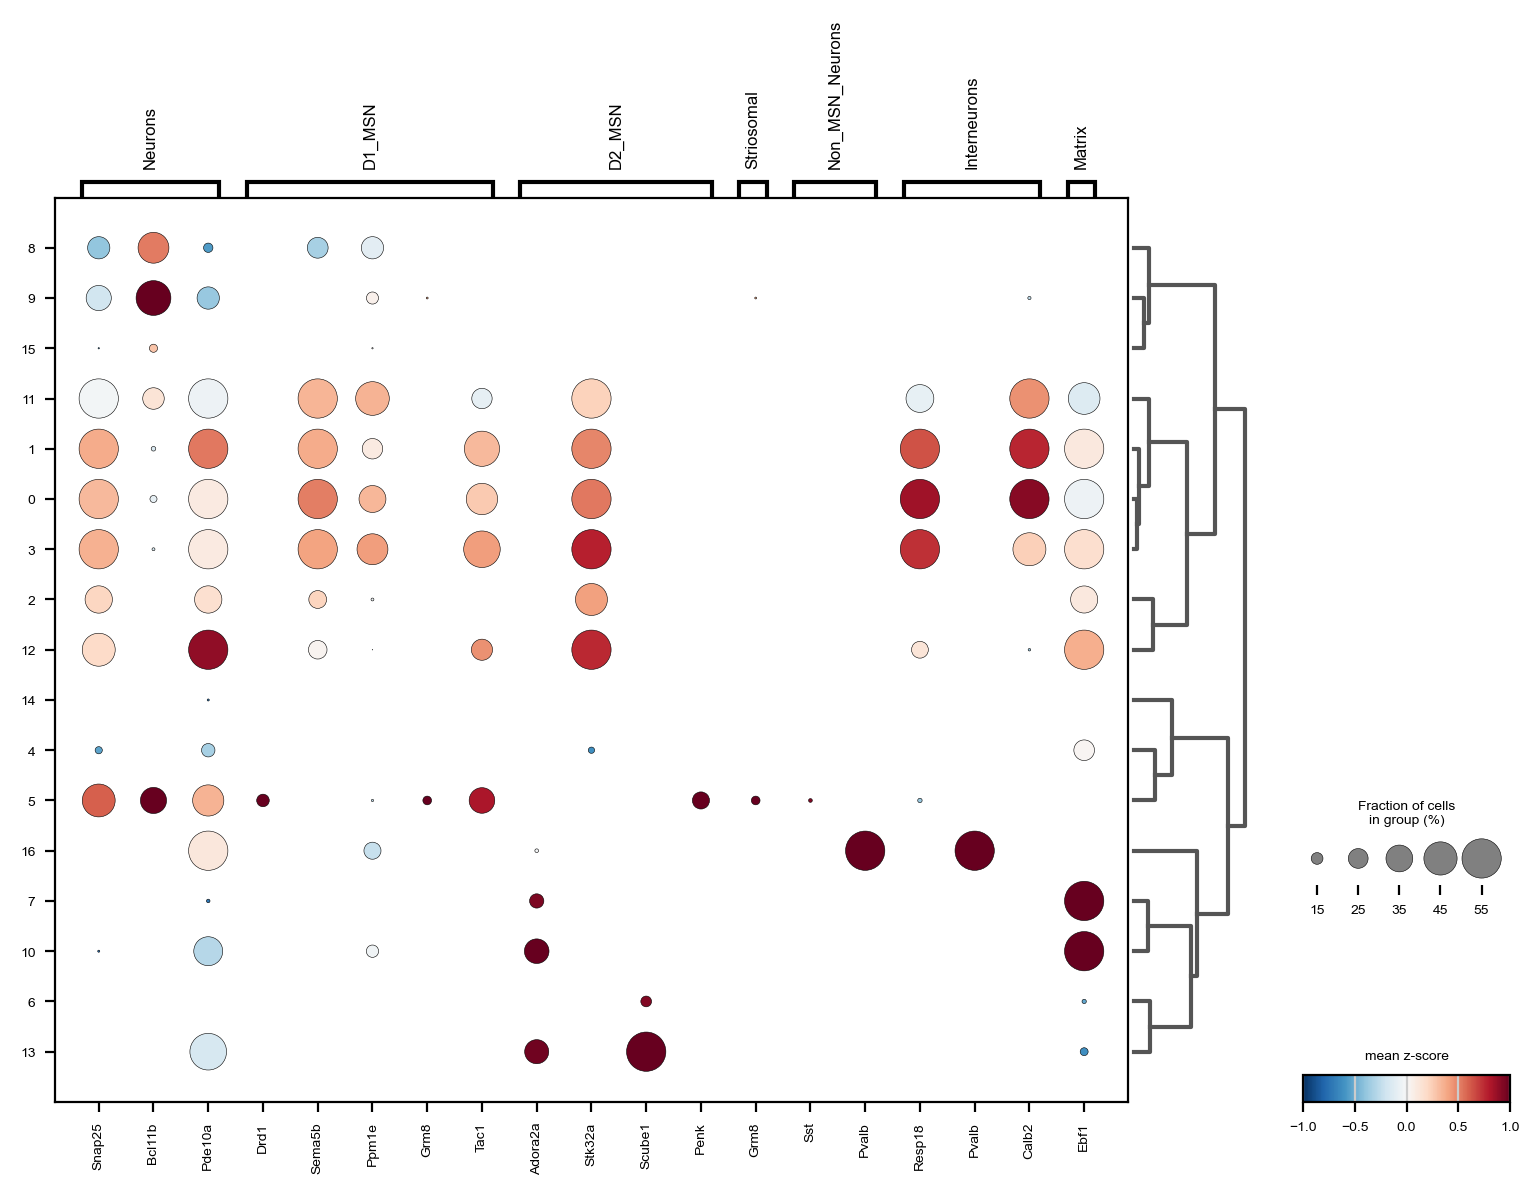

In [36]:
# name = '2023_05_19'

ax = sc.pl.dotplot(
    adata_neuron,
    # neuron_genes,
    na_markers,
    groupby=['leiden_neuron'],
    # swap_axes=True,
    dendrogram=True,
    colorbar_title='mean z-score',
    # show_gene_labels=True,
    layer='scaled',
    vmin=-1, vmax=1, 
    dot_min = 0.05,
    dot_max = 0.55,
    cmap='RdBu_r',
    # save = name,
    # return_fig=True
)
# ax.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5).show()
# !mv -v figures/dotplot_{name}.pdf celltyping/{name}_dotplot.pdf

In [53]:
# ax = sc.pl.heatmap(
#     adata_neuron,
#     neuron_genes,
#     groupby=['leiden_neuron'],
#     swap_axes=True,
#     dendrogram=True,
#     # colorbar_title='mean z-score',
#     show_gene_labels=True,
#     layer='scaled',
#     vmin=-1, vmax=1, #cmap='RdBu_r',
#     # save = 'neuron_new_markers'
#     # return_fig=True
# )
# # ax.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5).show()
# # !mv -v figures/dotplot_neuron_new_markers.pdf celltyping/neuron_new_markers_dotplot_v3.pdf
# # !mv -v figures/heatmapneuron_new_markers.pdf celltyping/neuron_new_markers_heatmap_v4.pdf

/data_gilbert/home/aarab/miniconda3/envs/scez/lib/python3.11/site-packages/anndata/compat/_overloaded_dict.py:106: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  self.data[key] = value
/data_gilbert/home/aarab/miniconda3/envs/scez/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/miniconda3/envs/scez/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/miniconda3/envs/scez/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


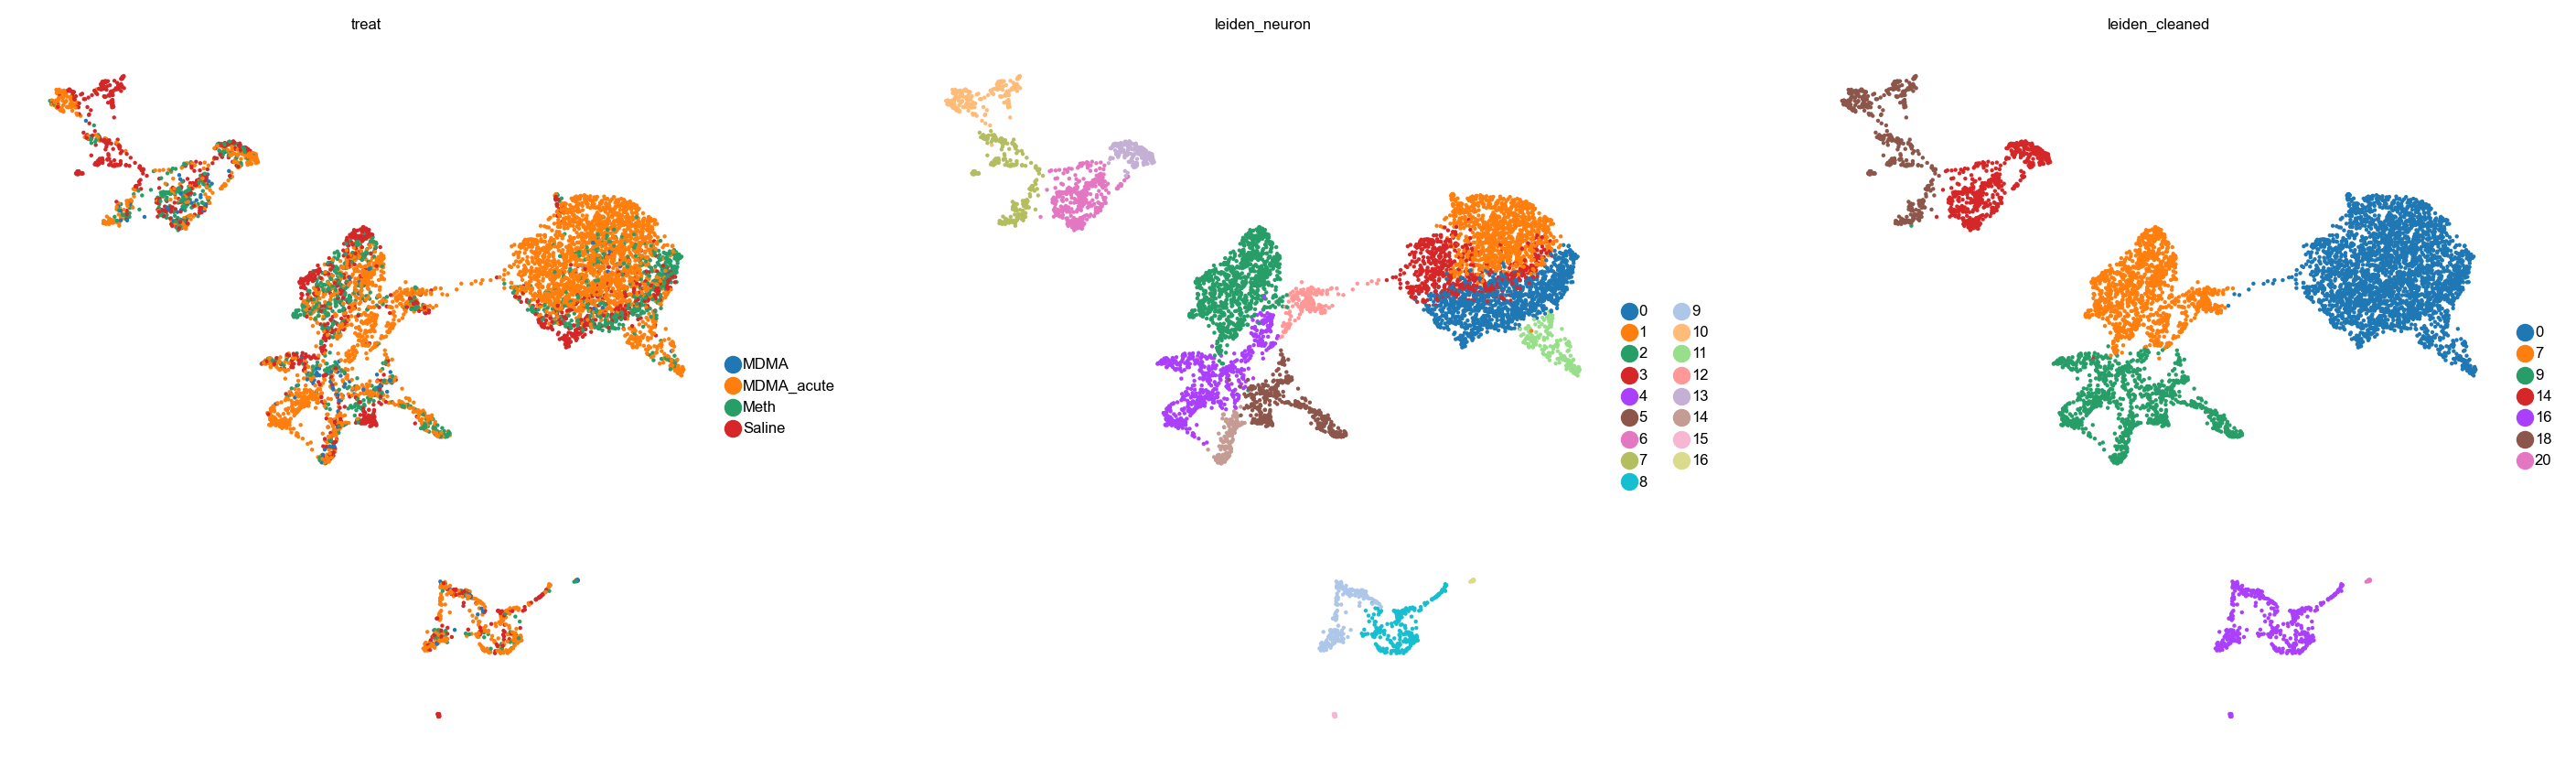

In [42]:
# name = '2023_05_19_umap_neuron_sub_clusters'

fig = sc.pl.umap(
    adata_neuron[random_indices],
    color=[
        'treat','leiden_neuron','leiden_cleaned'
        # "Kcnc1", "Acan", "Pvalb", "Junb",
        # "Egr4", 
        # "Homer2", 
        # "Homer3", 
    ],
    # vmin=0,vmax=3,
    color_map="Reds",
    frameon=False,alpha=1,size=10,
    return_fig=True
    # legend_loc='on data',
    # add_outline=0.1
    # save = name
)

# fig.savefig(f'celltyping/{name}_umap.pdf',dpi = 700)

In [43]:
# sc.pl.umap(
#     adata_neuron,
#     color=[
#         'leiden_scVI',
#         'leiden_neuron',
#         'label',
#         # 'mean_counts',
#         "Foxp1",
#         "Kcnc1", "Acan", "Pvalb", "Junb",
#         "Snap25",'Sox11',
#         "Mog","Ptprb",
#         'group',
#     ],
#     # vmax=2,
#     # vmin=0,
#     color_map="Reds",
#     frameon=False,alpha=0.5,size=30,
#     # legend_loc='on data',
#     add_outline=0.1
# )

In [24]:
# sc.pl.umap(
#     adata_neuron,
#     color=['Snap25','Sox11','Grin3a','Apod',#'Gria1',
#            'Gt(ROSA)26Sor',
#            'group',"leiden_scVI",'leiden_neuron'],
#     vmax=1,
#     vmin=0,
#     color_map="Reds",
#     frameon=False,alpha=0.5,size=10,
#     # legend_loc='on data',
#     # add_outline=0.1
# )

In [25]:
# sc.pl.umap(
#     adata_neuron,
#     color=[
#         'group','leiden_neuron'
#     ],
#     vmin=0,vmax=1,
#     color_map="Reds",
#     frameon=False,alpha=0.5,size=10,
#     # legend_loc='on data',
#     # add_outline=0.1
# )

###

In [56]:
# adata_neuron.var.loc[["Drd1", "Drd2", "Adora2a", "Ppp1r1b"],]

In [33]:
# for gene in ["Drd1", "Drd2", "Adora2a", "Ppp1r1b"]:
#     _ = scez.utils.add_marker_feature(adata_neuron,marker=gene,marker_name=f'{gene} label',clusters_name='leiden_neuron')
#     # plt.savefig(f'celltyping/adata_neuron_percent_in_clust_{gene}.pdf')
#     plt.show()

### Conditions within sub-clusters

In [58]:
# # name = 'neuron_sub_clusters'

# fig = sc.pl.umap(
#     adata_neuron,
#     color=[
#         'treat','leiden_neuron',
#         "Kcnc1", "Acan", "Pvalb", "Junb",
        
#         # "Egr4", 
#         # "Homer2", 
#         # "Homer3", 
#     ] + neuron_genes['Interneurons']
#     ,
#     vmin=0,vmax=3,
#     color_map="Reds",
#     frameon=False,alpha=1,size=10,
#     return_fig=True
#     # legend_loc='on data',
#     # add_outline=0.1
#     # save = name
# )

# # fig.savefig(f'celltyping/{name}_umap.pdf',dpi = 700)

In [59]:
# neuron_genes['Interneurons']

In [60]:
# name = 'neuron_sub_clusters'

# ax = sc.pl.heatmap(
#     adata_neuron,
#     [
#         "Kcnc1", "Acan", "Pvalb", "Junb",
#         # "Egr4", 
#         # "Homer2", 
#         # "Homer3", 
#     ] + neuron_genes['Interneurons']
#     , 
#     groupby=['leiden_neuron'],
#     swap_axes=True, 
#     dendrogram=True,
#     # colorbar_title='mean z-score', 
#     # standard_scale="var",
#     layer='scaled',
#     vmin=-2, vmax=2, 
#     cmap='RdBu_r',
#     save = f'_{name}'
# )

# !mv -v figures/heatmap_{name}.pdf celltyping/{name}_heatmap.pdf

In [61]:
# name = 'neuron_sub_clusters'

# ax = sc.pl.dotplot(
#     adata_neuron,
#     [
#         "Kcnc1", "Acan", "Pvalb", "Junb",
#         # "Egr4", 
#         # "Homer2", 
#         # "Homer3", 
#     ] + neuron_genes['Interneurons']
#     , 
#     groupby=['leiden_neuron'],
#     swap_axes=True, 
#     dendrogram=True,
#     colorbar_title='mean z-score', 
#     standard_scale="var",
#     dot_min = 0.05,
#     layer='scaled',
#     vmin=-1, vmax=1, 
#     cmap='RdBu_r',
#     save = f'{name}'
# )

# !mv -v figures/dotplot_{name}.pdf celltyping/{name}_dotplot.pdf

In [62]:
# rm figures/dotplot__neuron_sub_clusters.pdf

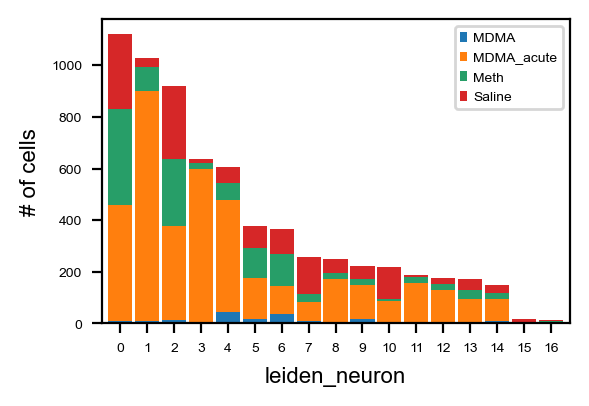

In [38]:
bar_plot_treat_in_clust(adata_neuron, 'leiden_neuron', y_type = '#',y_scale=False)

In [39]:
adata_neuron.obs.groupby(['treat']).size()

treat
MDMA           186
MDMA_acute    3928
Meth          1238
Saline        1368
dtype: int64

In [40]:
adata_neuron.obs.groupby(['leiden_neuron']).size()

leiden_neuron
0     1122
1     1030
2      919
3      637
4      608
5      376
6      367
7      256
8      250
9      221
10     217
11     186
12     175
13     174
14     150
15      18
16      14
dtype: int64

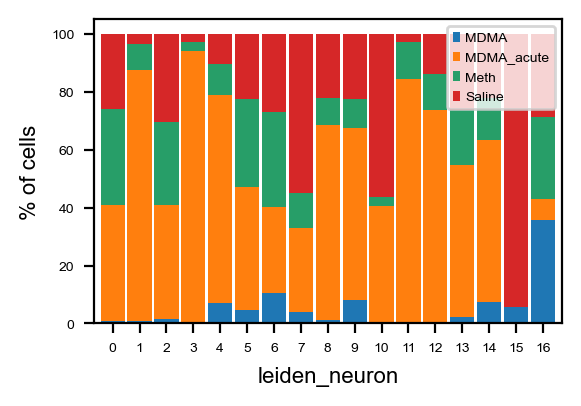

In [41]:
bar_plot_treat_in_clust(adata_neuron, 'leiden_neuron', y_type = '%',y_scale=False)

### Rank genes within sub-clusters

In [66]:
sc.tl.rank_genes_groups(
    adata_neuron, 'leiden_neuron', method='wilcoxon'
)

In [42]:
# # name = 'neuron_rank_genes'

# sc.tl.dendrogram(
#     adata_neuron, 
#     groupby=['leiden_neuron','treat'],
# )

# ax = sc.pl.rank_genes_groups_dotplot(
#     adata_neuron,
#     n_genes=20,
#     # new_markers,
#     groupby=['leiden_neuron','treat'],
#     # colorbar_title='mean z-score',
#     swap_axes=True,
#     dendrogram=True,
#     # colorbar_title='mean z-score',
#     # show_gene_labels=True,
#     layer='scaled',
#     vmin=-1, vmax=1, cmap='RdBu_r',
#     return_fig=True
# )
# fig = ax.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5)

# # fig.savefig(f'celltyping/{name}_dotplot.pdf')

# fig

In [41]:
# # name = 'neuron_rank_genes'

# ax = sc.pl.rank_genes_groups_heatmap(
#     adata_neuron,
#     n_genes=20,
#     # new_markers,
#     groupby=['leiden_neuron'],
#     # colorbar_title='mean z-score',
#     swap_axes=True,
#     dendrogram=True,
#     # colorbar_title='mean z-score',
#     show_gene_labels=True,
#     layer='scaled',
#     vmin=-1, vmax=1, cmap='RdBu_r',
#     save = f'_{name}',
#     return_fig=True
    
# )

# # !mv -v figures/heatmap_{name}.pdf celltyping/{name}_heatmap.pdf

In [ ]:
# !mv -v figures/heatmapneuron_new_markers.pdf celltyping/neuron_new_markers_heatmap_v4.pdf

In [82]:
ranked_neuron_clusters_full = scez.utils.rank_genes_to_df(
    adata_neuron, 
    n = 200
    # n = adata_neuron.var.shape[0]
)

In [83]:
ranked_neuron_clusters_full.to_csv('celltyping/ranked_neuron_clusters_full.csv')

In [25]:
# sc.tl.dendrogram(adata_neuron,'leiden_neuron')

In [26]:
# name = 'ranked_neuron_clusters_top'

# ax = sc.pl.dotplot(
#     adata_neuron, 
#     dict([(clust,genes.split(',')[:10]) for clust,genes in clusters_unique_ranked_genes.values]),
#     groupby=['leiden_neuron'], 
#     swap_axes=True, 
#     dendrogram=True,
#     colorbar_title='mean z-score', 
#     standard_scale="var",
#     vmin=-1, vmax=1, cmap='RdBu_r',
#     save = name
# )

# !mv -v figures/dotplot_{name}.pdf celltyping/{name}_dotplot.pdf

In [27]:
# # name = 'ranked_neuron_clusters_top'

# ax = sc.pl.dotplot(
#     adata_neuron, 
# dict([(clust,genes.split(',')[:5]) for clust,genes in clusters_unique_ranked_genes.values
#       if clust in ['5_names,2_names','14_names,4_names']]),
#     groupby=['leiden_neuron'],
#     swap_axes=True, 
#     dendrogram=True,
#     colorbar_title='mean z-score', 
#     standard_scale="var",
#     vmin=-1, vmax=1, cmap='RdBu_r',
#     # save = name
# )

# # !mv -v figures/dotplot_{name}.pdf celltyping/{name}_dotplot.pdf

In [28]:
# sc.tl.dendrogram(adata_neuron,'leiden_neuron')

In [29]:
# ax = sc.pl.dotplot(
#     adata_neuron, 
#     [gene for clust,genes in temp for gene in genes],# if clust in ['8_names','5_names','0_names',
#                                                                     # '1_names','2_names','4_names']], 
#     groupby=['leiden_neuron'], 
#     swap_axes=False, 
#     dendrogram=True,
#     colorbar_title='mean z-score', 
#     # layer='scaled', 
#     vmin=-4, vmax=4, cmap='RdBu_r',
#     # save = 'Snap25_neg'
# )

# # !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

rank_genes_groups_dotplot

In [ ]:
# ax = sc.pl.rank_genes_groups_dotplot(
#     adata_neuron, 
#     groupby=['leiden_neuron'],
#     swap_axes=True,
#     n_genes=5,
#     layer='scaled',
#     values_to_plot='logfoldchanges', min_logfoldchange=3,
#     vmin=-4, vmax=4, cmap='RdBu_r',
# )

In [ ]:
# ax = sc.pl.rank_genes_groups_dotplot(
#     adata_neuron, 
#     groupby=['leiden_neuron'],
#     n_genes=10,
#     values_to_plot='logfoldchanges', min_logfoldchange=3,
#     groups=['3','4'],
#     vmin=-4, vmax=4, cmap='RdBu_r',
# )

___

In [ ]:
ranked_neuron_clusters_top = ranked_neuron_clusters_full.filter(regex='names').iloc[:20,]

In [ ]:
ranked_neuron_clusters_top_rev = revert_upset_dataframe(
    from_contents(ranked_neuron_clusters_top)
)

In [ ]:
clusters_unique_ranked_genes = pd.concat([
    get_intersection(from_contents(ranked_neuron_clusters_top)),
    # get_intersection(from_contents(ranked_neuron_clusters_top),which='7_names,13_names,0_names'),
    # get_intersection(from_contents(ranked_neuron_clusters_top),which='13_names,9_names'),
    # get_intersection(from_contents(ranked_neuron_clusters_top),which='0_names,7_names'),
    # get_intersection(from_contents(ranked_neuron_clusters_top),which='14_names,4_names'),
    # get_intersection(from_contents(ranked_neuron_clusters_top),which='5_names,2_names'),
])

In [ ]:
# Create a Pandas Excel writer using XlsxWriter as the engine.
writer = pd.ExcelWriter('celltyping/ranked_neuron_clusters_top-v2.xlsx', engine='xlsxwriter')

# Write each dataframe to a different worksheet.
ranked_neuron_clusters_full.to_excel(writer, sheet_name='full')
clusters_unique_ranked_genes.set_index('cluster_vs_all').to_excel(writer, sheet_name='clusters_unique_ranked_genes')

# Close the Pandas Excel writer and output the Excel file.
writer.save()

In [29]:
# upset = UpSet(
#     from_contents(ranked_neuron_clusters_top),
#     # min_degree=2, 
#     subset_size='count',
#     min_subset_size=25, 
#     show_counts=True,
# ).plot()

# plt.savefig('celltyping/ranked_neuron_clusters_top_largest.pdf',font_size=10)

In [30]:
# upset = UpSet(
#     from_contents(ranked_neuron_clusters_top),
#     # min_degree=2, 
#     subset_size='count',
#     # min_subset_size=25, 
#     show_counts=True,
# ).plot()

# plt.savefig('celltyping/ranked_neuron_clusters_top_all.pdf',font_size=10)

### 

> - [ ] Subcluster neuronal clusters 0, 1 and 3 and generate a UMAP displaying treatment conditions to see if we can better separate MDMA and Meth activated cells

In [92]:
adata_neuron_013 = adata_neuron[adata_neuron.obs.leiden_neuron.isin(['0','1','3'])].copy()

In [93]:
adata_neuron_013

AnnData object with n_obs × n_vars = 8443 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Sox11 label', 'TdT label', 'label', 'leiden_neuron', 'treat', 'Drd1 label', 'Drd2 label', 'Adora2a label', 'Ppp1r1b label'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'leiden', 'leiden_neuron_colors', 'neighbors', 'pca', 'umap', 'dendrogram_leiden_neuron', 'group_colors', 'treat_colors'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    varm: 'PCs'
    layers: 'counts', 'scvi_normalized', 'scaled'
    obsp: 'connectivities', 'distances'

#### sub-clustering

In [94]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_neuron_013, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

In [95]:
adata_neuron_013

AnnData object with n_obs × n_vars = 8443 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Sox11 label', 'TdT label', 'label', 'leiden_neuron', 'treat', 'Drd1 label', 'Drd2 label', 'Adora2a label', 'Ppp1r1b label'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'leiden', 'leiden_neuron_colors', 'neighbors', 'pca', 'umap', 'dendrogram_leiden_neuron', 'group_colors', 'treat_colors'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    varm: 'PCs'
    layers: 'counts', 'scvi_normalized', 'scaled'
    obsp: 'connectivities', 'distances'

In [96]:
sc.tl.pca(adata_neuron_013)

In [97]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata_neuron_013, use_rep="X_scVI")
sc.tl.umap(adata_neuron_013, min_dist=0.1)

In [98]:
# neighbors were already computed using scVI
sc.tl.leiden(adata_neuron_013, key_added="leiden_neuron_013", resolution=0.5)

/opt/anaconda3/envs/mamba/envs/sc-analysis/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/opt/anaconda3/envs/mamba/envs/sc-analysis/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/opt/anaconda3/envs/mamba/envs/sc-analysis/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


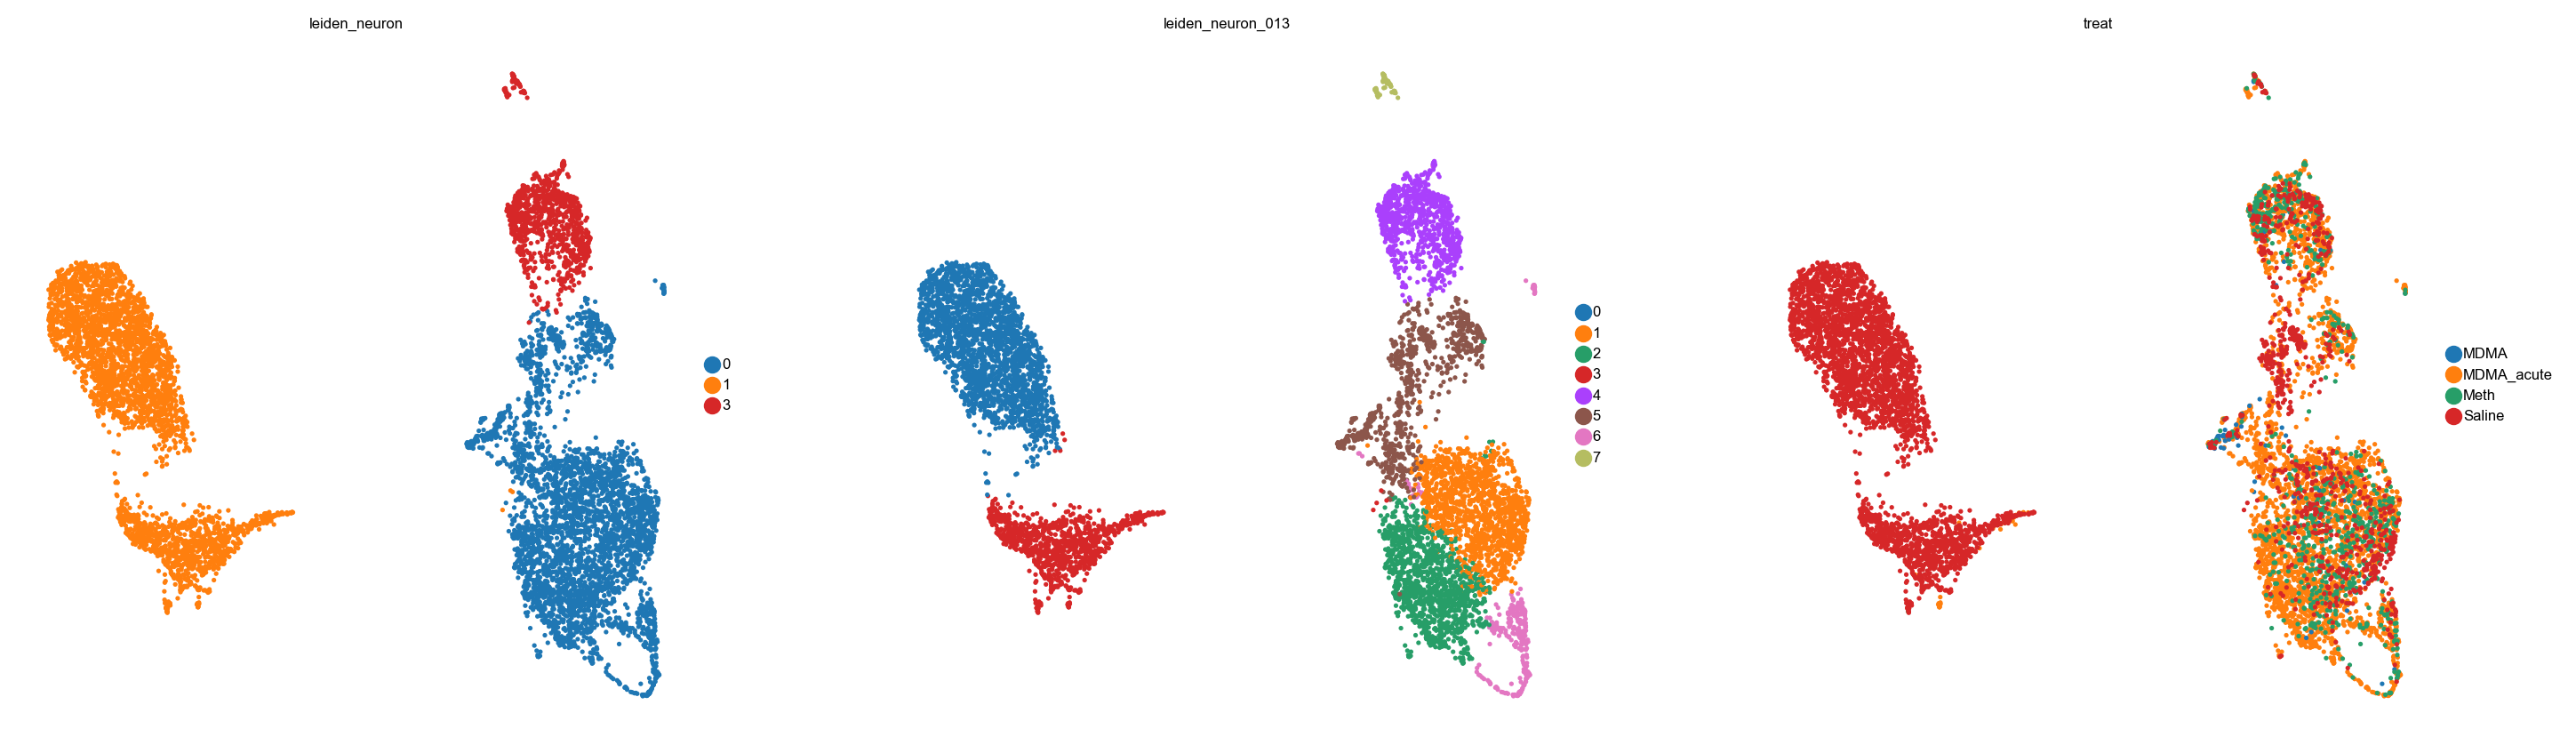

In [99]:
sc.pl.umap(adata_neuron_013, color=['leiden_neuron', 'leiden_neuron_013', 'treat'])

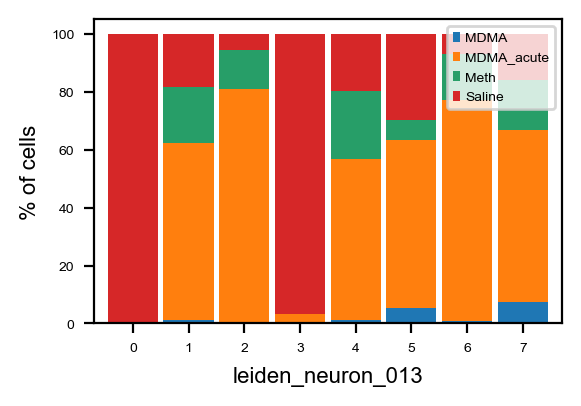

In [100]:
bar_plot_treat_in_clust(adata_neuron_013, 'leiden_neuron_013', y_type = '%', y_scale = False)

### GSEA

___
`down` env

In [1]:
import pandas as pd 

In [2]:
import blitzgsea as blitz

In [3]:
ranked_neuron_clusters_full = pd.read_csv('celltyping/ranked_neuron_clusters_full.csv',index_col=0)

In [4]:
c5_gmt = blitz.enrichr.read_gmt(
    # '/data_gilbert/home/aarab/Projects/'
    '../' +
    'pager/annotations/human/msigdb_v7.4_c5.go/c5.go.v7.4.symbols.gmt'
)

In [5]:
c2_gmt = blitz.enrichr.read_gmt(
    # '/data_gilbert/home/aarab/Projects/'
    '../' +
    'pager/annotations/human/msigdb_v7.4_c2.cp.kegg/c2.cp.kegg.v7.4.symbols.gmt'
)

___

In [6]:
syngo = pd.read_csv('../synGOpy/syngo_ontologies_clean.txt',sep='\t').set_index('name').rename(columns={'hgnc_symbol':'genes'})

syngo_gmt = syngo.genes.str.split(', ').to_dict()

In [ ]:
ranked_neuron_clusters_full

In [ ]:
GSEA_res = {}

for i in range(0,ranked_neuron_clusters_full.shape[1],2):
    n = ranked_neuron_clusters_full.columns[i].split('_')[0]
    GSEA_res[f'{n}_clust'] = {}

    signature = ranked_neuron_clusters_full.iloc[:,[i,i+1]].copy()
    signature.iloc[:,0] = signature.iloc[:,0].str.upper()
    result = blitz.gsea(signature,syngo_gmt,max_size=50,verbose=True ,min_size=5,seed=-1)
    result = result[(result.nes.gt(0))] #  & (result.fdr.le(0.2))
    GSEA_res[f'{n}_clust'] = {
        'signature':signature,
        'result':result,
    }

In [ ]:
signature.iloc[:,1]

___

In [ ]:
fig_compact = blitz.plot.running_sum(
    GSEA_res['0_clust']['signature'], 
    "synapse adhesion between pre- and post-synapse (GO:0099560)", 
    library=syngo_gmt, 
    result=GSEA_res['0_clust']['result'], 
    compact=True
)

fig_compact.savefig(
    'celltyping/ranked_neuron_clusters_GO_example_clust0_compact.pdf',
    bbox_inches='tight'
)

fig_compact
# fig = blitz.plot.running_sum(GSEA_res['0_clust']['signature'], "GOCC_INTRINSIC_COMPONENT_OF_SYNAPTIC_MEMBRANE", 
#                              library=m5_gmt, 
#                              result=GSEA_res['0_clust']['result'], 
#                              compact=False)

# fig.savefig(
#     'celltyping/ranked_neuron_clusters_GO_example_clust0.pdf',
#     bbox_inches='tight'
# )

In [ ]:
writer = pd.ExcelWriter('celltyping/ranked_neuron_clusters_GO.xlsx', engine='xlsxwriter')
ranked_neuron_clusters_full.to_excel(writer, sheet_name='genes')

for clust in GSEA_res:
    GSEA_res[clust]['result'].to_excel(writer, sheet_name=clust)
writer.save()

### 
___

# 

In [19]:
!date

Tue Feb 21 11:51:15 PST 2023
